In [1]:

import baostock as bs
import pandas as pd
import numpy as np
import time
from datetime import datetime,timedelta
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.sans-serif'] = ['Microsoft YaHei']
rcParams['axes.unicode_minus'] = False

from matplotlib import rcParams  # 字体
from unicodedata import normalize



In [2]:
def get_trade_days(start_date,end_date):
    bs.login()
    rs = bs.query_trade_dates(start_date=start_date,end_date=end_date)
    dates = []
    while rs.error_code == '0' and rs.next():
        row = rs.get_row_data()
        if row[1] == '1':
            dates.append(row[0])

    monthly_dates = []
    current_month = ''
    for d in dates:
        month = d[:7]
        if month != current_month:
            monthly_dates.append(d)
            current_month = month
    bs.logout()
    return monthly_dates




In [3]:
def get_momentum(code,date,window=20):
    end_dt = pd.to_datetime(date)
    start_dt = end_dt - timedelta(days=window + 10)

    rs = bs.query_history_k_data_plus(
        code,'date,close',
        start_date = start_dt.strftime('%Y-%m-%d'),
        end_date = date,
        frequency='d'
    )
    data = []
    while rs.error_code == '0' and rs.next():
        data.append(rs.get_row_data())

    if len(data) < window + 1:

        return None

    df = pd.DataFrame(data,columns=rs.fields)
    df['close']=pd.to_numeric(df['close'])

    return (df['close'].iloc[-1])/df['close'].iloc[-window] * 100



In [4]:
def select_stocks(trade_date,stock_pool,top_n=5):
    """
    多因子选股
    - pe = get_pe(code,trade_date)#估值
    - roe = get_roe(code,trade_date)#盈利
    - score = 0.4*roe_rank+0.3*pe_rank+0.3*momentum_rank
    :param trade_date:
    :param stock_pool:
    :param top_n:
    :return:
    """
    results = []
    for code in stock_pool[:30]:
        mom = get_momentum(code,trade_date)
        if mom is  not None:
            results.append({'code':code,'momentum':mom})
    df = pd.DataFrame(results)
    if df.empty:
        return pd.DataFrame()
    df = df.sort_values('momentum',ascending=False)
    return df.head(top_n)

login success!
logout success!
login success!

===调仓日:2023-01-03===
选中：['sh.600027', 'sh.600036', 'sh.600011', 'sh.600023', 'sh.600029']
策略净值：0.9750| 基准净值：1.0792

===调仓日:2023-02-01===
本月无有效数据，跳过

===调仓日:2023-03-01===
选中：['sh.600118', 'sh.600066', 'sh.600031', 'sh.600160', 'sh.600050']
策略净值：0.9815| 基准净值：1.0697

===调仓日:2023-04-03===
选中：['sh.600066', 'sh.600085', 'sh.600028', 'sh.600039', 'sh.600029']
策略净值：1.0779| 基准净值：1.0539

===调仓日:2023-05-04===
本月无有效数据，跳过

===调仓日:2023-06-01===
选中：['sh.600150', 'sh.600027', 'sh.600118', 'sh.600023', 'sh.600025']
策略净值：1.1150| 基准净值：1.0778

===调仓日:2023-07-03===
本月无有效数据，跳过

===调仓日:2023-08-01===
选中：['sh.600030', 'sh.600019', 'sh.600048', 'sh.600160', 'sh.600061']
策略净值：1.1038| 基准净值：1.0221

===调仓日:2023-09-01===
选中：['sh.600160', 'sh.600048', 'sh.600025', 'sh.600085', 'sh.600028']
策略净值：1.0711| 基准净值：0.9933

===调仓日:2023-10-09===
本月无有效数据，跳过

===调仓日:2023-11-01===
本月无有效数据，跳过

===调仓日:2023-12-01===
选中：['sh.600025', 'sh.600150', 'sh.600027', 'sh.600160', 'sh.600015']
策略

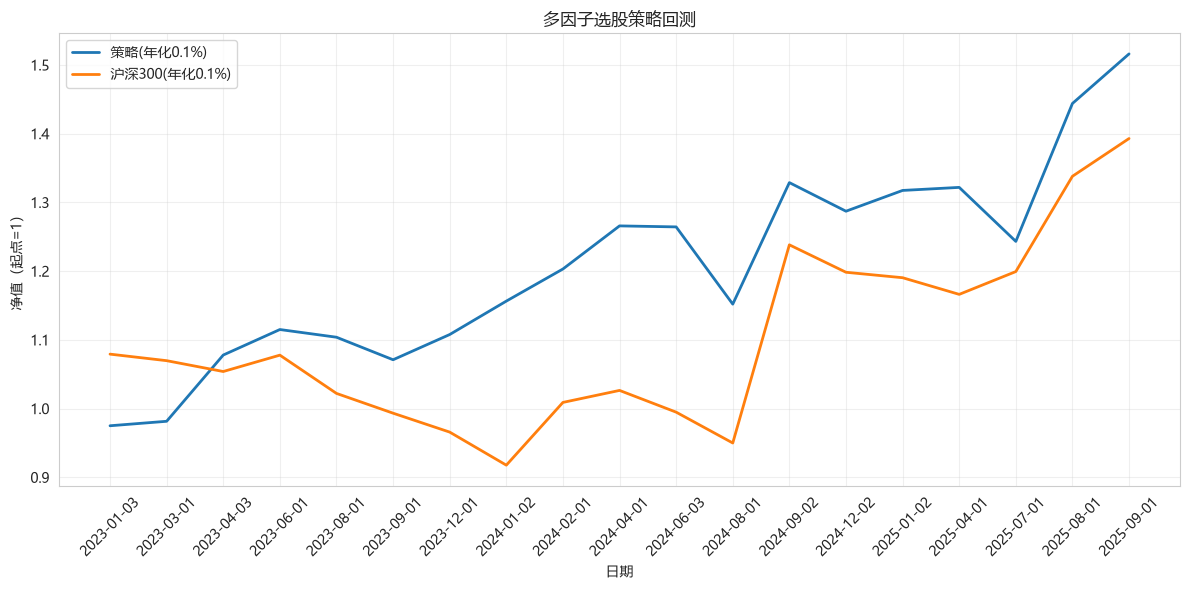

\n==================================================
📊 回测绩效报告
策略年化收益: 14.88%
基准年化收益: 11.68%
超额收益: 3.20%
最大回撤: 8.99%


In [5]:
def backtest(start_date,end_date,top_n=5):
    trade_days = get_trade_days(start_date,end_date)
    bs.login()
    rs = bs.query_hs300_stocks()
    stock_list = []
    while rs.error_code == '0' and rs.next():
        stock_list.append(rs.get_row_data())
    stock_pool = pd.DataFrame(stock_list,columns=rs.fields)['code'].tolist()

    portfolio_value = 1.0
    benchmark_value = 1.0
    portfolio_records = []
    benchmarke_records = []
    dates_records = []

    for i in range(len(trade_days)-1):
        current_date = trade_days[i]
        next_date = trade_days[i+1]
        print(f'\n===调仓日:{current_date}===')

        selected = select_stocks(current_date,stock_pool,top_n)

        if selected.empty:
            print('本月无有效数据，跳过')
            continue

        print(f'选中：{selected['code'].tolist()}')

        month_return = 0
        valid = 0
        for _,row in selected.iterrows():
            code = row['code']
            rs = bs.query_history_k_data_plus(
                code,
                'date,close',
                start_date=current_date,
                end_date=next_date,
                frequency='d',
            )
            data = []
            while rs.error_code == '0' and rs.next():
                data.append(rs.get_row_data())
            if len(data) >= 2:
                df = pd.DataFrame(data,columns=rs.fields)
                df['close']=pd.to_numeric(df['close'])
                ret = df['close'].iloc[-1]/df['close'].iloc[0] - 1
                month_return += ret
                valid+=1
        if valid > 0:
            month_return = month_return / valid
        portfolio_value *= (1+month_return)

        rs = bs.query_history_k_data_plus(
            'sh.000300','date,close',
            start_date=current_date,
            end_date=next_date,
            frequency='d',

        )
        data = []
        while rs.error_code == '0' and rs.next():
            data.append(rs.get_row_data())
        if len(data) >= 2:
            df = pd.DataFrame(data,columns=rs.fields)
            df['close']=pd.to_numeric(df['close'])
            bench_ret = df['close'].iloc[-1]/df['close'].iloc[0] - 1
            benchmark_value *= (1+bench_ret)

        portfolio_records.append(portfolio_value)
        benchmarke_records.append(benchmark_value)
        dates_records.append(current_date)

        print(f'策略净值：{portfolio_value:.4f}| 基准净值：{benchmark_value:.4f}')

    bs.logout()
#画图
#年化收益
    n_years = len(trade_days) / 12
    strategy_annual = (portfolio_value ** (1/n_years) - 1)
    benchmark_annual = (benchmark_value ** (1/n_years) - 1)
    #最大回撤
    strategy_dd = max_drawdown(portfolio_records)

    plt.figure(figsize = (12,6))
    plt.plot(dates_records,portfolio_records,label=f'策略(年化{strategy_annual:.1f}%)',linewidth=2)
    plt.plot(dates_records,benchmarke_records,label=f'沪深300(年化{benchmark_annual:.1f}%)',linewidth=2)
    plt.title('多因子选股策略回测')
    plt.xlabel('日期')
    plt.ylabel('净值（起点=1）')
    plt.legend()
    plt.grid(True,alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    # ... 前面代码不变 ...


# ========== 新增：打印绩效报告 ==========
    print("\\n" + "=" * 50)
    print("📊 回测绩效报告")
    print("=" * 50)
    print(f"策略年化收益: {strategy_annual * 100:.2f}%")
    print(f"基准年化收益: {benchmark_annual * 100:.2f}%")
    print(f"超额收益: {(strategy_annual - benchmark_annual) * 100:.2f}%")
    print(f"最大回撤: {strategy_dd:.2f}%")

def max_drawdown(values):
    """计算最大回撤"""
    peak = values[0]
    max_dd = 0
    for v in values[1:]:
        if v > peak:
            peak = v
        dd = (peak - v) / peak
        if dd > max_dd:
            max_dd = dd
    return max_dd * 100

backtest('2023-01-01','2025-12-31',top_n=5)



